In [1]:
!pip install kagglehub roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 98.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [2]:
import kagglehub
import os

path = kagglehub.dataset_download('arunrk7/surface-crack-detection')
print('Dataset Path: ', path)
print(f'Folders: {os.listdir( path )}')


Using Colab cache for faster access to the 'surface-crack-detection' dataset.
Dataset Path:  /kaggle/input/surface-crack-detection
Folders: ['Negative', 'Positive']


In [ ]:
# Configuration — edit these values for your own project
WORKSPACE_NAME = 'mohamed-s-workspace-nwimv'
PROJECT_NAME = 'concrete-crack-segmentation-uuzho'
IMAGES_PER_CLASS = 700

In [4]:
from google.colab import userdata

api_key = userdata.get('ROBOFLOW_API_KEY')
print('Done', len(api_key))


Done 20


In [6]:
# Upload a balanced sample of filtered images to Roboflow, class by class
from roboflow import Roboflow

rf = Roboflow( api_key=api_key )

project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

loading Roboflow workspace...
loading Roboflow project...


In [8]:
uploaded_count = 0

for fld in os.listdir( path ):

  fld_path = os.path.join( path , fld )
  print(f'Folder Name: {fld}')
  print(f'Folder Path: {fld_path}')

  all_files = [ img for img in os.listdir( fld_path ) if img.lower().endswith(('jpg' , 'jpeg' , 'png'))]

  selected_files = all_files[ : IMAGES_PER_CLASS ]

  print(f"Uploading {len(selected_files)} images from class: {fld}")

  for file in selected_files :

    file_path = os.path.join( fld_path , file )
    project.upload( file_path , batch_name=fld )

    uploaded_count += 1

  print(f"  Done with {fld}. Total uploaded so far: {uploaded_count}")

print(f"\nUpload finished. Total images uploaded: {uploaded_count}")


loading Roboflow workspace...
loading Roboflow project...
Folder Name: Negative
Folder Path: /kaggle/input/surface-crack-detection/Negative
Folder Name: Positive
Folder Path: /kaggle/input/surface-crack-detection/Positive
Uploading 300 images from class: Positive
  Done with Positive. Total uploaded so far: 300

Upload finished. Total images uploaded: 300


In [7]:
version = project.version(1)
dataset = version.download('yolo26')

Exporting format yolo26 in progress : 92.0%
Version export complete for yolo26 format



Extracting Dataset Version Zip to concrete-crack-segmentation-1 in yolo26:: 100%|██████████| 2192/2192 [00:00<00:00, 6908.87it/s]


In [8]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 11.0 MB/s eta 0:00:00


In [11]:
from ultralytics import YOLO

base_model = YOLO('yolo26n-seg.pt')


In [12]:
base_model.train( data='/content/concrete-crack-segmentation-1/data.yaml' ,
                         epochs = 100 , imgsz= 640 , batch = 16
                )

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/concrete-crack-segmentation-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None,

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c0d57e43e70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [17]:
model = YOLO('/content/runs/segment/train/weights/best.pt')
metrics = model.val(split='test', conf= 0.40)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,689,079 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 834.7±474.4 MB/s, size: 30.5 KB)
val: Scanning /content/concrete-crack-segmentation-1/test/labels.cache... 110 images, 42 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 110/110 18.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.2it/s 6.0s
                   all        110        103      0.876      0.689      0.685       0.59      0.833      0.728      0.702      0.541
Speed: 13.7ms preprocess, 10.1ms inference, 0.0ms loss, 6.3ms postprocess per image
Results saved to /content/runs/segment/val-2


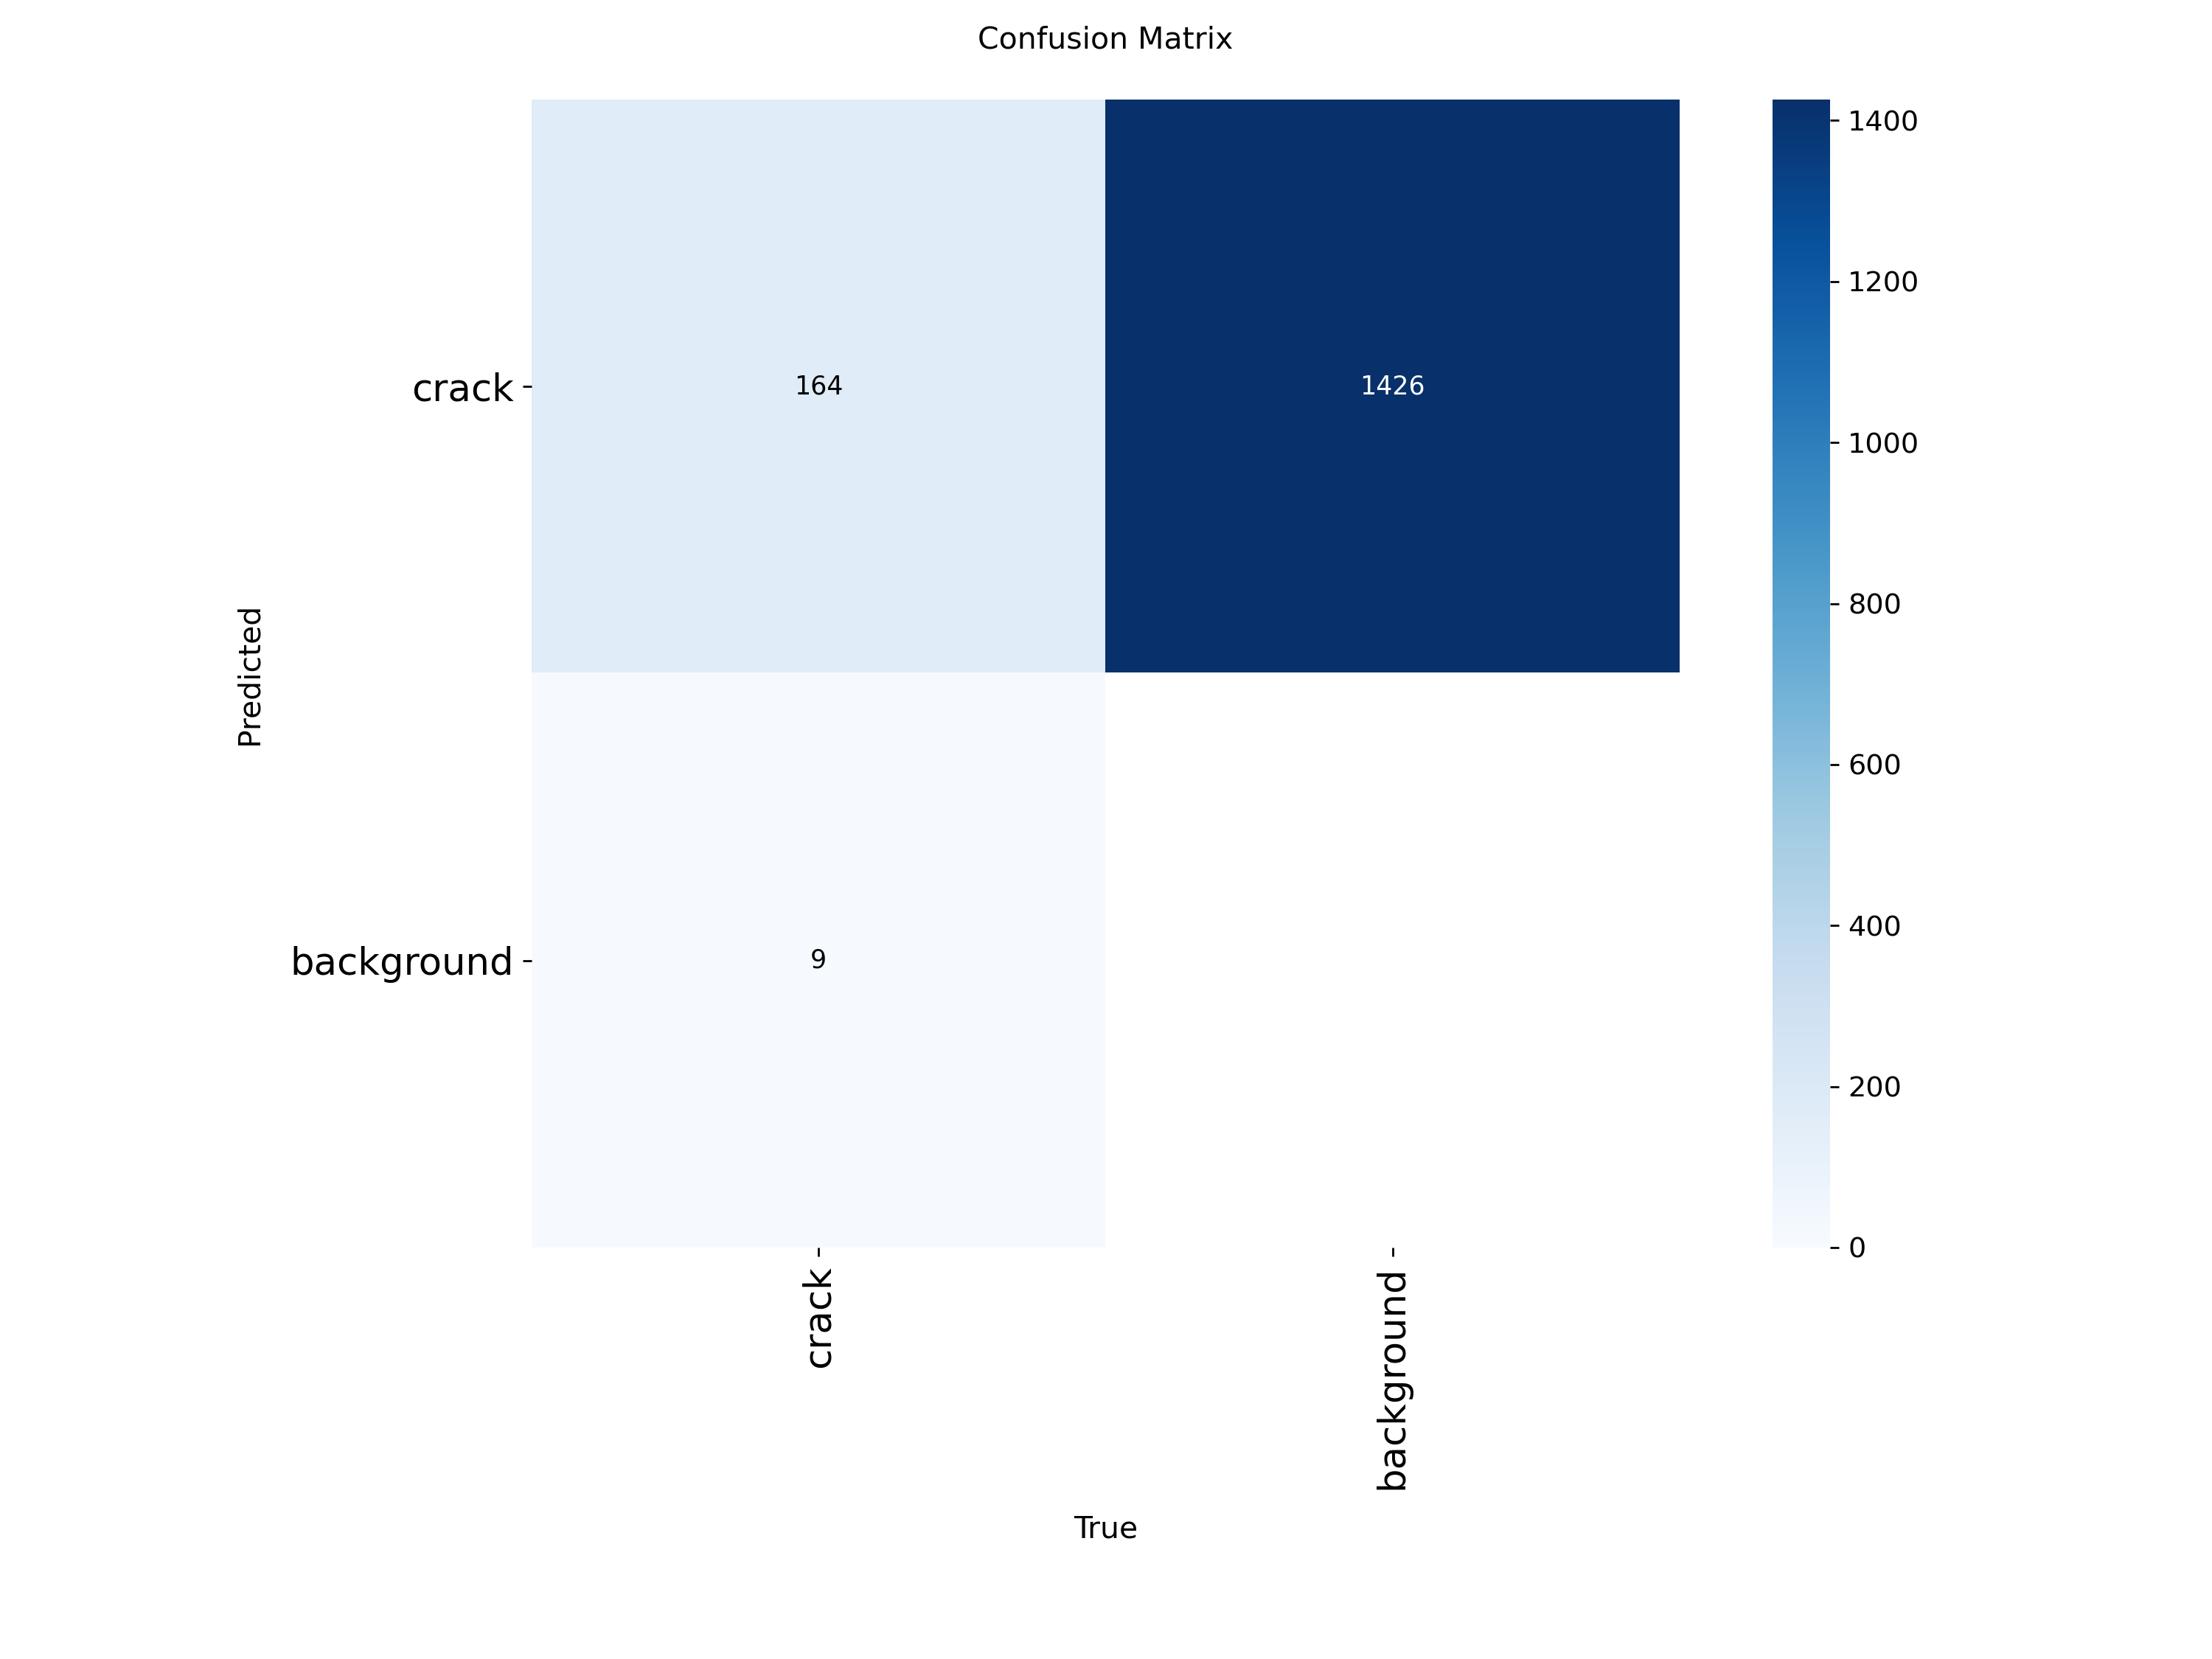

In [19]:
from IPython.display import display , Image

display( Image('/content/runs/segment/train/confusion_matrix.png') )

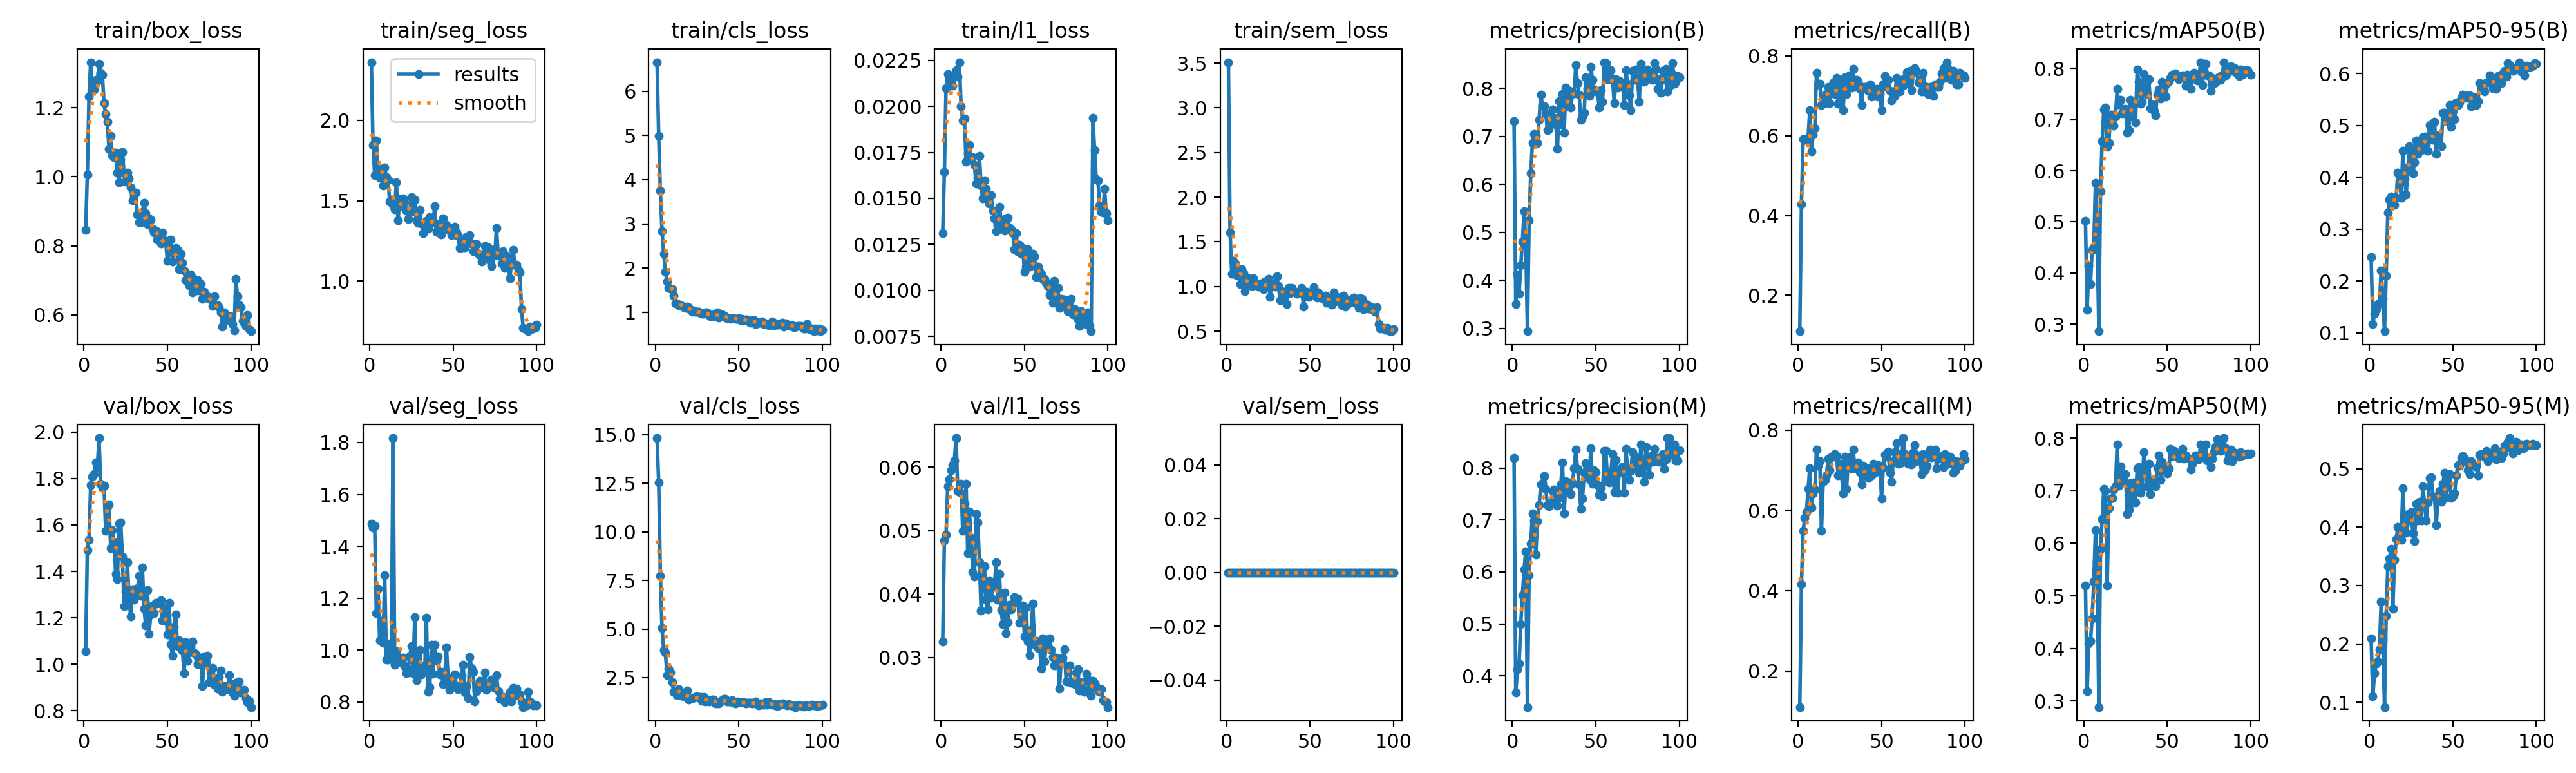

In [20]:
display( Image('/content/runs/segment/train/results.png') )

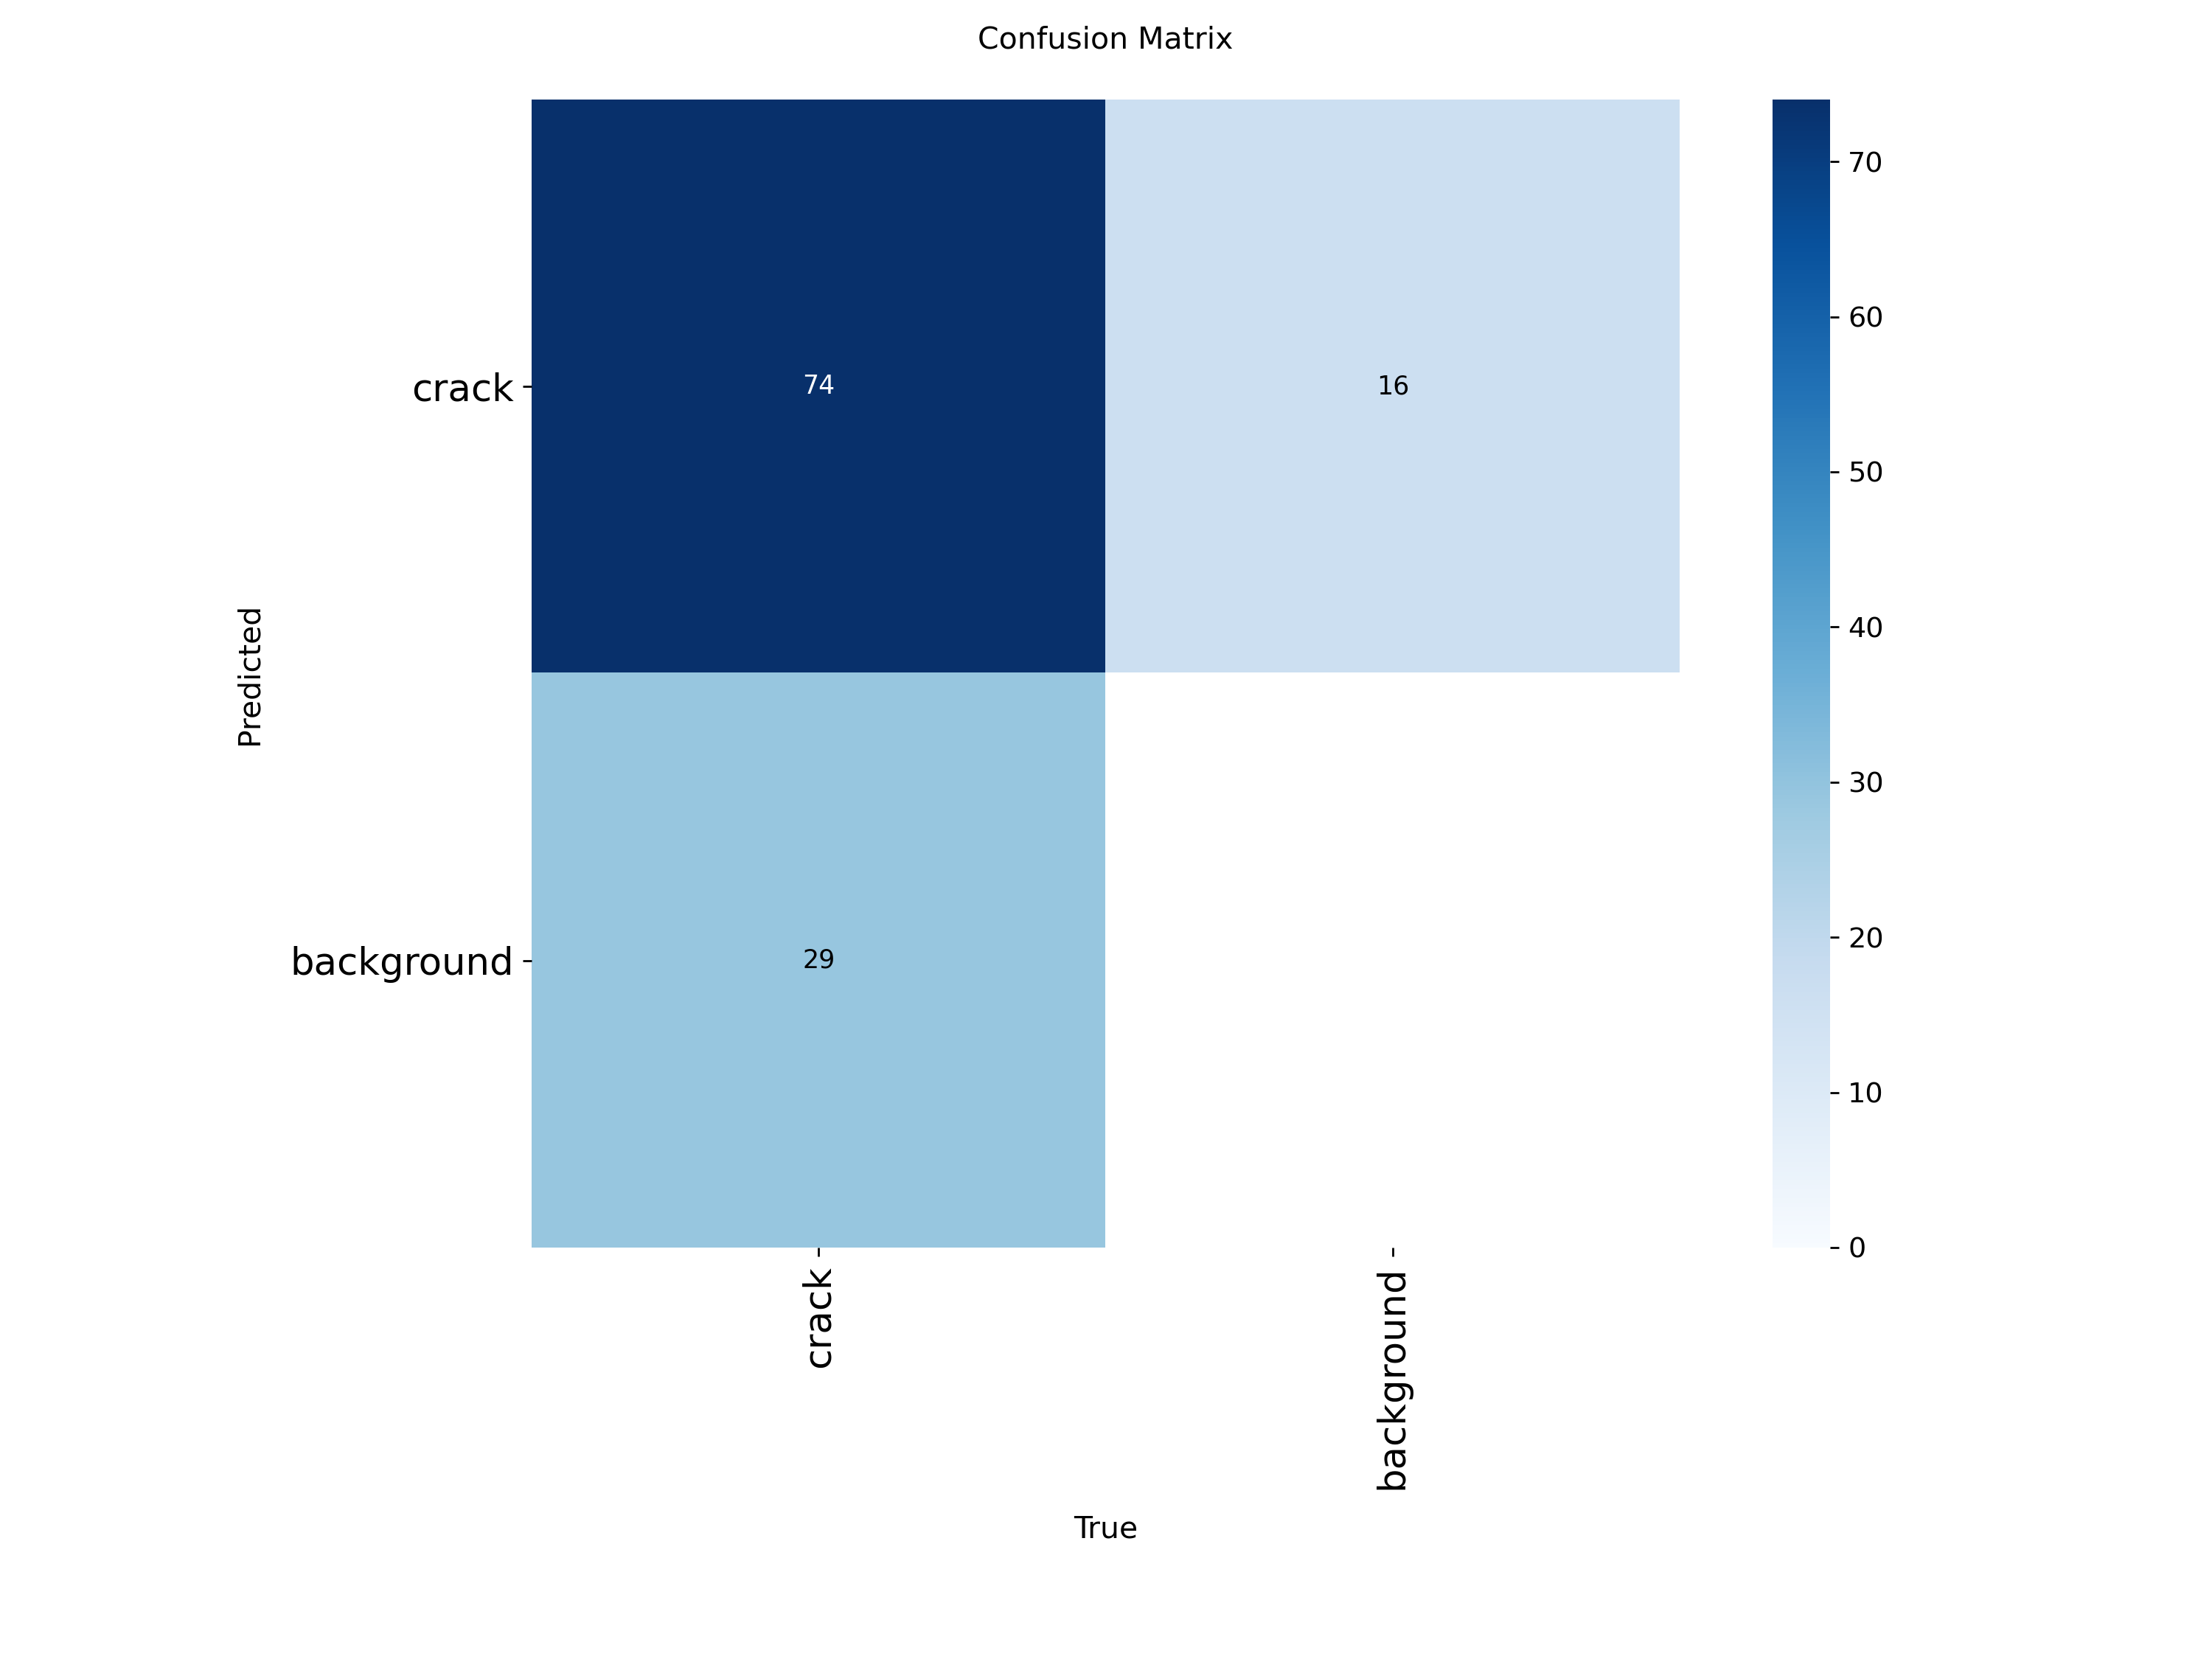

In [26]:
display( Image('/content/runs/segment/val-2/confusion_matrix.png' , width = 800))


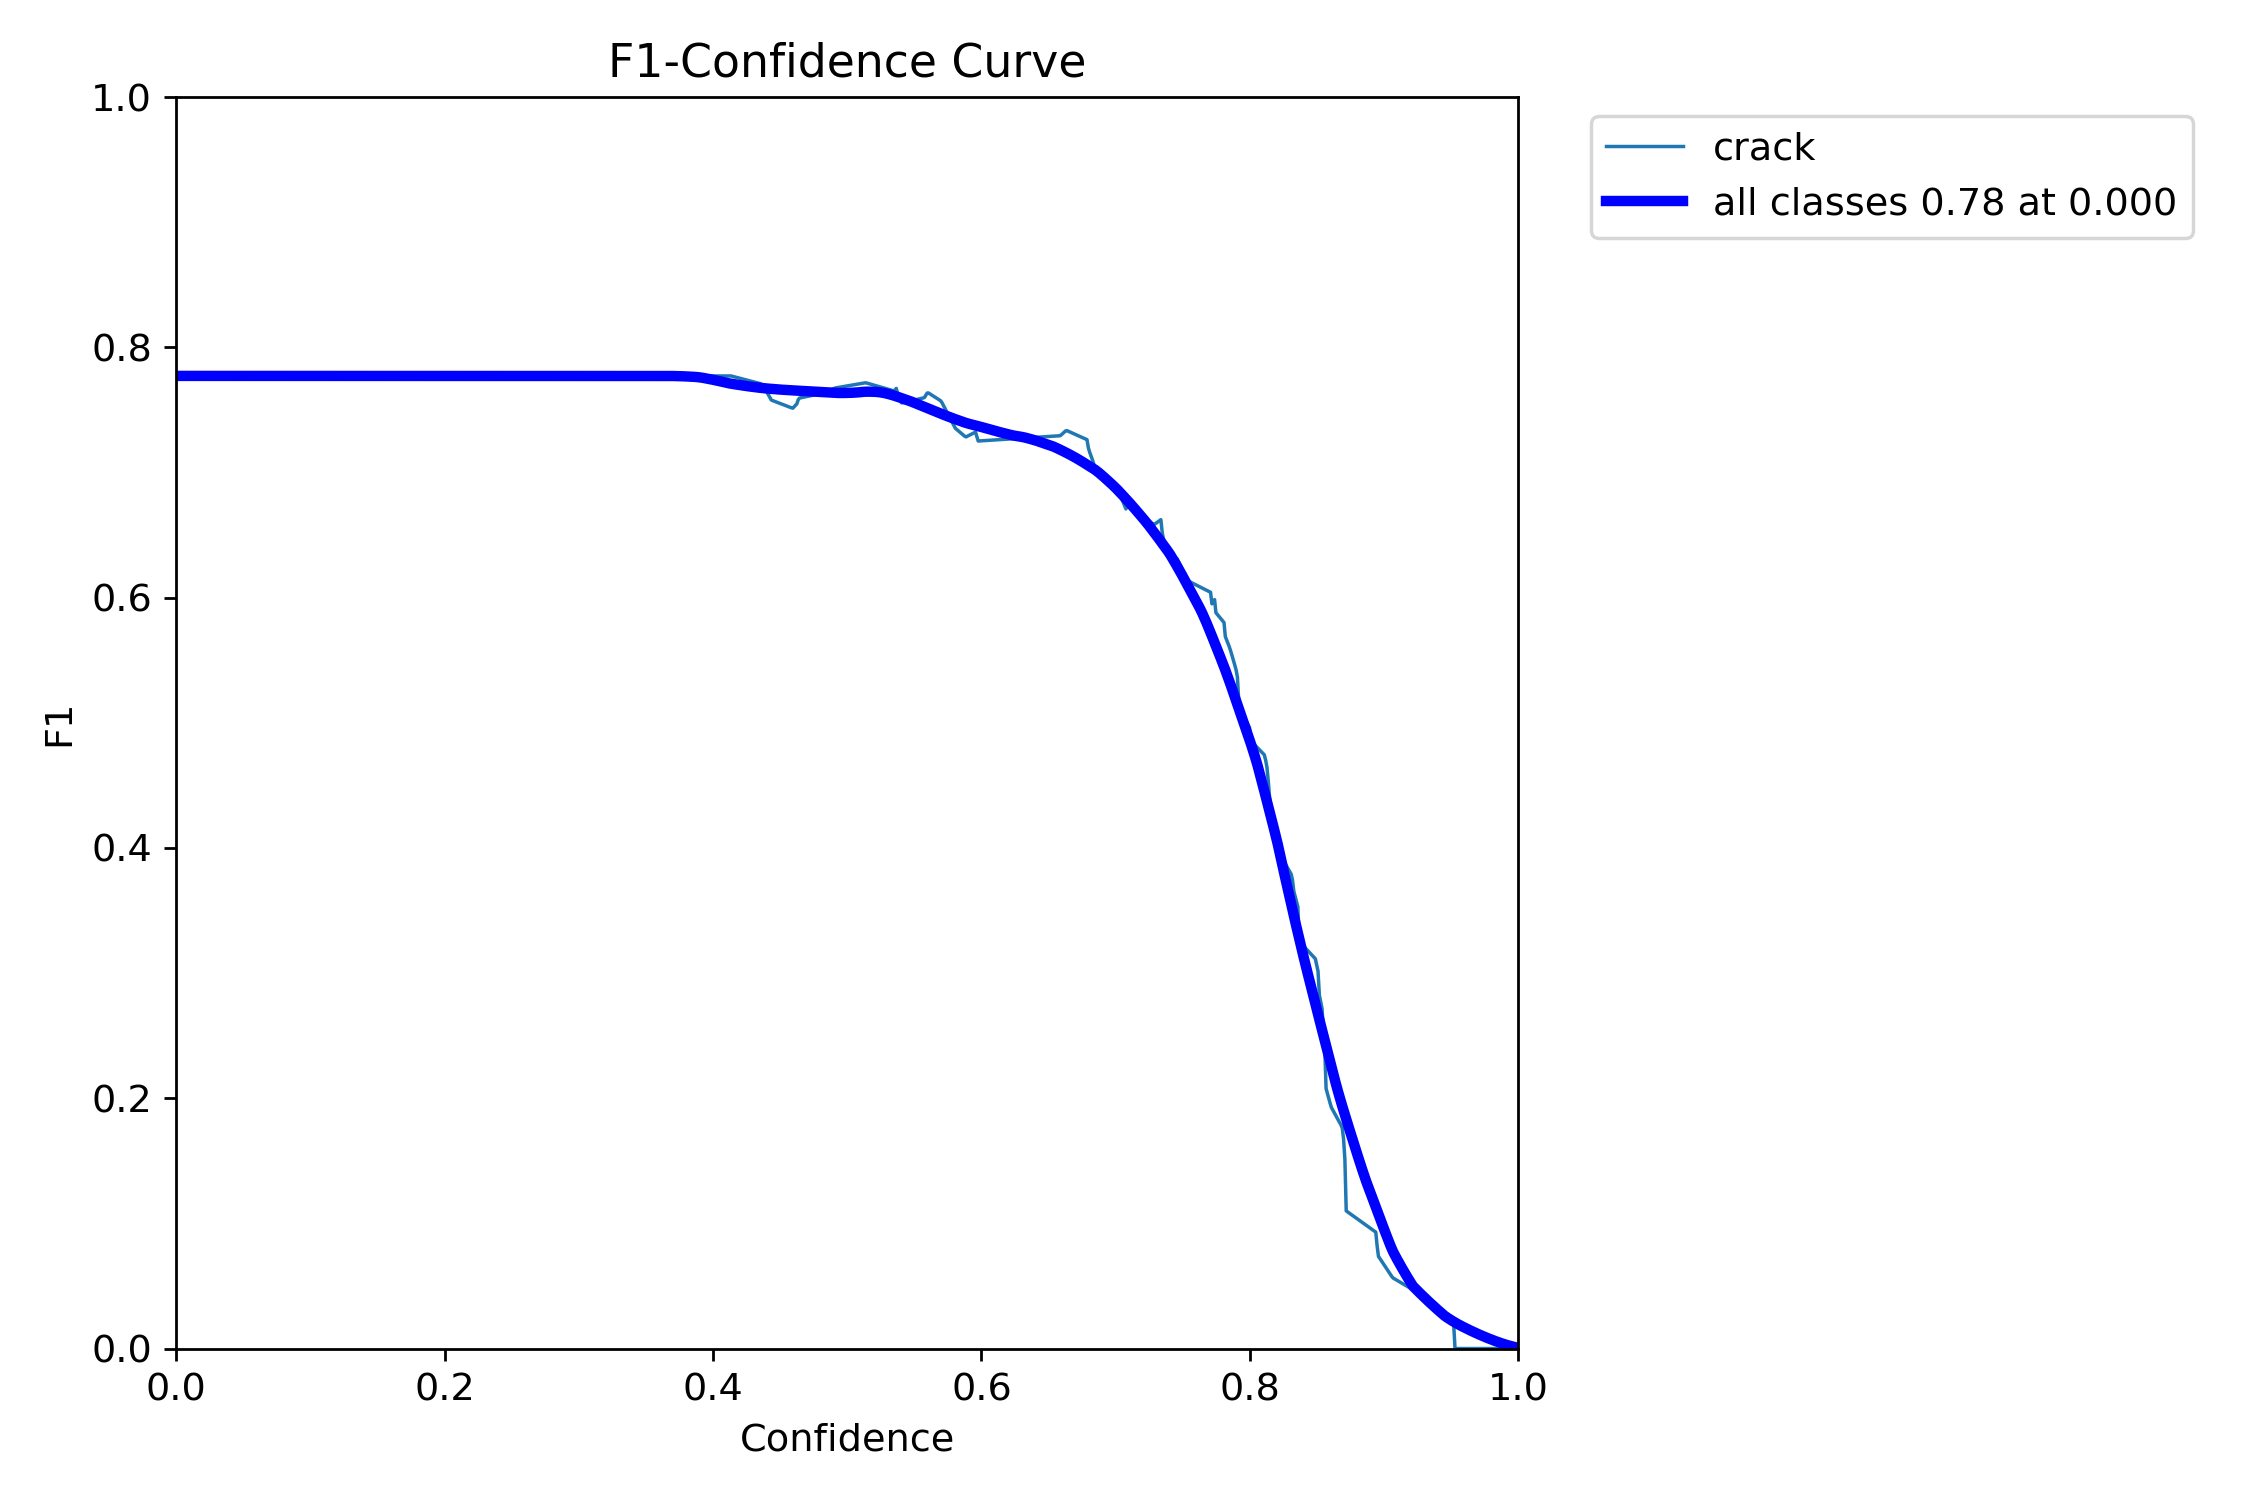

In [27]:
display( Image('/content/runs/segment/val-2/MaskF1_curve.png', width = 800 ) )
